# NutriVision AI: Notebook 1 -- Dataset Exploration & Annotation Validation

**Project:** NutriVision AI -- AI-Powered Food Recognition and Nutrition Analysis  
**Dataset:** `SohlHealth/enhanced-indian-food-classification` (Hugging Face)  
**Target Platform:** Google Colab (with GPU acceleration) / Local Jupyter

---

### Objectives:
1. **Download & Inspect Dataset:** Download the primary image dataset from Hugging Face and inspect directory structure, metadata, and files.
2. **Annotation Capabilities Audit (Critical Requirement):**
   - Check whether the dataset contains image-level classification labels, bounding boxes, segmentation masks, or multi-food labels per image.
   - Rigorously test and report the schema.
3. **Class & Split Analysis:** Quantify images per class across train, validation, and test splits; check class coverage and detect split defects.
4. **Data Quality & Integrity:** Check for corrupted images, irregular image dimensions, non-RGB channels, and duplicate images.
5. **Visualization:** Visualize sample images across various classes and plot the class distribution.
6. **Export Metadata:** Export validated class list (`class_names.json`) and exploration findings (`dataset_exploration_summary.json`).


## 1. Environment Setup & Dependency Installation

In [16]:
# Install required packages in Google Colab environment
!pip install --quiet datasets huggingface_hub pyarrow pillow matplotlib seaborn pandas tqdm tabulate

import os
import sys
import json
import hashlib
from io import BytesIO
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
from huggingface_hub import HfApi, hf_hub_download
from datasets import load_dataset

# Hardware and environment verification
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch Version: {torch.__version__}")
print(f"Device: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


PyTorch Version: 2.11.0+cpu
Device: cpu



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Hugging Face Dataset Metadata & File Structure Inspection

In [17]:
DATASET_REPO = "SohlHealth/enhanced-indian-food-classification"
api = HfApi()

# Inspect repository metadata and file list
repo_files = api.list_repo_files(DATASET_REPO, repo_type="dataset")
print(f"Repository: {DATASET_REPO}")
print(f"Total files in repository: {len(repo_files)}")
for f in repo_files:
    print(f"  - {f}")


Repository: SohlHealth/enhanced-indian-food-classification
Total files in repository: 9
  - .gitattributes
  - README.md
  - data/test-00000-of-00001.parquet
  - data/train-00000-of-00003.parquet
  - data/train-00001-of-00003.parquet
  - data/train-00002-of-00003.parquet
  - data/validation-00000-of-00001.parquet
  - dataset_info.json
  - statistics/dataset_stats.json


### Inspect Remote Metadata Files (`dataset_info.json` & `statistics/dataset_stats.json`)

In [18]:
# Download dataset_info.json
try:
    info_path = hf_hub_download(DATASET_REPO, "dataset_info.json", repo_type="dataset")
    with open(info_path, "r", encoding="utf-8") as f:
        dataset_info = json.load(f)
    print("--- Remote dataset_info.json Metadata ---")
    print(json.dumps(dataset_info, indent=2))
except Exception as e:
    print("dataset_info.json could not be loaded:", e)

# Download statistics/dataset_stats.json
try:
    stats_path = hf_hub_download(DATASET_REPO, "statistics/dataset_stats.json", repo_type="dataset")
    with open(stats_path, "r", encoding="utf-8") as f:
        dataset_stats = json.load(f)
    print("\n--- Remote dataset_stats.json Metadata ---")
    print(f"Total Reported Images: {dataset_stats.get('total_images')}")
    print(f"Total Reported Classes: {dataset_stats.get('total_classes')}")
except Exception as e:
    print("dataset_stats.json could not be loaded:", e)


--- Remote dataset_info.json Metadata ---
{
  "dataset_name": "Indian Food Detection Dataset",
  "description": "Comprehensive Indian food detection dataset with YOLO annotations",
  "version": "1.0.0",
  "license": "cc-by-4.0",
  "task": "object-detection",
  "language": "en",
  "size_categories": "43 classes",
  "total_images": 0,
  "splits": {
    "train": 0,
    "validation": 0,
    "test": 0
  },
  "classes": [
    "aloo_gobi",
    "aloo_masala",
    "bhindi_masala",
    "biryani",
    "burger",
    "butter_naan",
    "chai",
    "chapati",
    "chicken_curry",
    "chole",
    "chole_bhature",
    "coconut_chutney",
    "dal_makhani",
    "dhokla",
    "dum_aloo",
    "fish_curry",
    "fried_rice",
    "ghevar",
    "green_chutney",
    "gulab_jamun",
    "idli",
    "jalebi",
    "kaathi_rolls",
    "kadai_paneer",
    "kebab",
    "kheer",
    "kulfi",
    "lassi",
    "masala_dosa",
    "modak",
    "momos",
    "mutton_curry",
    "paani_puri",
    "pakode",
    "palak_panee

## 3. Dataset Loading & Feature Schema Inspection

In [19]:
print("Loading dataset from Hugging Face...")
raw_dataset = load_dataset(DATASET_REPO)
print("\nDataset loaded successfully:")
print(raw_dataset)
print("\nFeature Schema per split:")
for split, ds in raw_dataset.items():
    print(f"Split [{split}]: {len(ds)} samples | Features: {ds.features}")


Loading dataset from Hugging Face...

Dataset loaded successfully:
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 13311
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 1067
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1026
    })
})

Feature Schema per split:
Split [train]: 13311 samples | Features: {'image': Image(mode=None, decode=True), 'label': Value('string')}
Split [validation]: 1067 samples | Features: {'image': Image(mode=None, decode=True), 'label': Value('string')}
Split [test]: 1026 samples | Features: {'image': Image(mode=None, decode=True), 'label': Value('string')}


## 4. CRITICAL AUDIT: Annotation Capabilities Validation

**Critical Requirement:**
- Check whether the dataset contains:
  1. Image-level classification labels.
  2. Bounding-box annotations (`[x, y, w, h]` or `[xmin, ymin, xmax, ymax]`).
  3. Segmentation masks / polygon vertices.
  4. Multiple food labels per image.
- **Rule:** Do NOT treat classification labels as object detection annotations. If it only contains image-level labels, do NOT train YOLO directly on those labels.


In [20]:
sample_train = raw_dataset["train"][0]
print("Sample train record keys:", list(sample_train.keys()))
print("Sample train label:", repr(sample_train["label"]), "Type:", type(sample_train["label"]))
print("Sample train image:", type(sample_train["image"]), "Size:", sample_train["image"].size, "Mode:", sample_train["image"].mode)

# Audit verification tests
has_bbox = any(k in sample_train for k in ["bbox", "boxes", "annotations", "objects", "coordinates"])
has_masks = any(k in sample_train for k in ["mask", "masks", "segmentation", "polygons"])
is_multilabel = isinstance(sample_train["label"], (list, tuple, set))

print("\n" + "="*70)
print("CRITICAL ANNOTATION AUDIT RESULTS:")
print(f"  - Bounding Box Annotations Present: {has_bbox}")
print(f"  - Segmentation Masks Present:       {has_masks}")
print(f"  - Multi-Label Annotations Present:  {is_multilabel}")
print(f"  - Single Image-Level Class Label:   {isinstance(sample_train['label'], (str, int))}")
print("="*70)

print("""
[AUDIT CONCLUSION & ARCHITECTURAL DECISION]:
1. Despite dataset_info.json referencing task: 'object-detection' and format: 'YOLO',
   the ACTUAL dataset schema consists purely of single-label image classification pairs:
   {'image': PIL.Image, 'label': str}.
2. ZERO bounding-box or segmentation annotations exist in this dataset.
3. Therefore, YOLO cannot and must not be trained directly on this dataset without synthetic or manual bounding boxes.
4. An image classification model (MobileNetV2 / ResNet50) is the scientifically valid architecture for this dataset.
5. To support multi-food plate images (e.g. an Indian thali), the Streamlit frontend must provide a manual
   crop/region selection interface so individual food regions can be classified independently.
""")


Sample train record keys: ['image', 'label']
Sample train label: 'jalebi' Type: <class 'str'>
Sample train image: <class 'PIL.JpegImagePlugin.JpegImageFile'> Size: (640, 640) Mode: RGB

CRITICAL ANNOTATION AUDIT RESULTS:
  - Bounding Box Annotations Present: False
  - Segmentation Masks Present:       False
  - Multi-Label Annotations Present:  False
  - Single Image-Level Class Label:   True

[AUDIT CONCLUSION & ARCHITECTURAL DECISION]:
1. Despite dataset_info.json referencing task: 'object-detection' and format: 'YOLO',
   the ACTUAL dataset schema consists purely of single-label image classification pairs:
   {'image': PIL.Image, 'label': str}.
2. ZERO bounding-box or segmentation annotations exist in this dataset.
3. Therefore, YOLO cannot and must not be trained directly on this dataset without synthetic or manual bounding boxes.
4. An image classification model (MobileNetV2 / ResNet50) is the scientifically valid architecture for this dataset.
5. To support multi-food plate image

## 5. Split Audit & Missing Class Discovery

Let us audit the distributions across the pre-defined `train`, `validation`, and `test` splits.


In [21]:
split_labels = {}
for split_name in raw_dataset.keys():
    split_labels[split_name] = [item["label"] for item in raw_dataset[split_name]]

all_unique_classes = sorted(list(set(split_labels["train"] + split_labels.get("validation", []) + split_labels.get("test", []))))
print(f"Total Unique Food Classes across entire dataset: {len(all_unique_classes)}")

# Create summary table per split
split_summary = []
for split_name, labels in split_labels.items():
    cnt = Counter(labels)
    split_summary.append({
        "Split": split_name,
        "Total Images": len(labels),
        "Unique Classes Present": len(cnt),
        "Classes Missing": len(all_unique_classes) - len(cnt)
    })

df_split_summary = pd.DataFrame(split_summary)
print("\n--- SPLIT AUDIT SUMMARY ---")
print(df_split_summary.to_string(index=False))

# Identify which classes are missing in validation and test
train_classes = set(split_labels["train"])
val_classes = set(split_labels.get("validation", []))
test_classes = set(split_labels.get("test", []))

missing_in_val = train_classes - val_classes
missing_in_test = train_classes - test_classes

print(f"\nClasses present in Train but MISSING in Validation ({len(missing_in_val)} classes):")
print(sorted(list(missing_in_val)))

print(f"\nClasses present in Train but MISSING in Test ({len(missing_in_test)} classes):")
print(sorted(list(missing_in_test)))


Total Unique Food Classes across entire dataset: 43

--- SPLIT AUDIT SUMMARY ---
     Split  Total Images  Unique Classes Present  Classes Missing
     train         13311                      43                0
validation          1067                      22               21
      test          1026                      22               21

Classes present in Train but MISSING in Validation (21 classes):
['aloo_gobi', 'aloo_masala', 'bhindi_masala', 'biryani', 'chicken_curry', 'chole', 'coconut_chutney', 'dum_aloo', 'fish_curry', 'ghevar', 'green_chutney', 'kebab', 'kheer', 'lassi', 'mutton_curry', 'palak_paneer', 'poha', 'rajma_curry', 'ras_malai', 'shahi_paneer', 'white_rice']

Classes present in Train but MISSING in Test (21 classes):
['aloo_gobi', 'aloo_masala', 'bhindi_masala', 'biryani', 'chicken_curry', 'chole', 'coconut_chutney', 'dum_aloo', 'fish_curry', 'ghevar', 'green_chutney', 'kebab', 'kheer', 'lassi', 'mutton_curry', 'palak_paneer', 'poha', 'rajma_curry', 'ras_malai',

### Critical Split Finding & Preprocessing Mandate
> [!WARNING]
> **Severe Upstream Split Flaw Discovered:**
> The upstream repository has an incomplete split distribution:
> - The `validation` split contains **only 22 out of 43 classes** (1,067 images).
> - The `test` split contains **the exact same 22 classes** (1,026 images).
> - **21 entire classes (6,000 images) are present ONLY in the train split!**
> 
> **Consequence:** If models were evaluated on these original splits, 21 classes would have zero validation and test performance metrics!
> 
> **Required Remediation (Notebook 2):**
> We must pool the entire 15,404 dataset and generate a clean, stratified train/validation/test split (70% / 15% / 15%) across **all 43 classes** to evaluate model generalization properly without data leakage.


## 6. Overall Class Distribution & Imbalance Analysis

Total Images: 15404
Max class count: 811 (chole_bhature)
Min class count: 130 (paani_puri)
Class Imbalance Ratio: 6.24x


C:\Users\anish\AppData\Local\Temp\ipykernel_6692\1426322809.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_dist, x="Image Count", y="Food Class", palette="viridis")


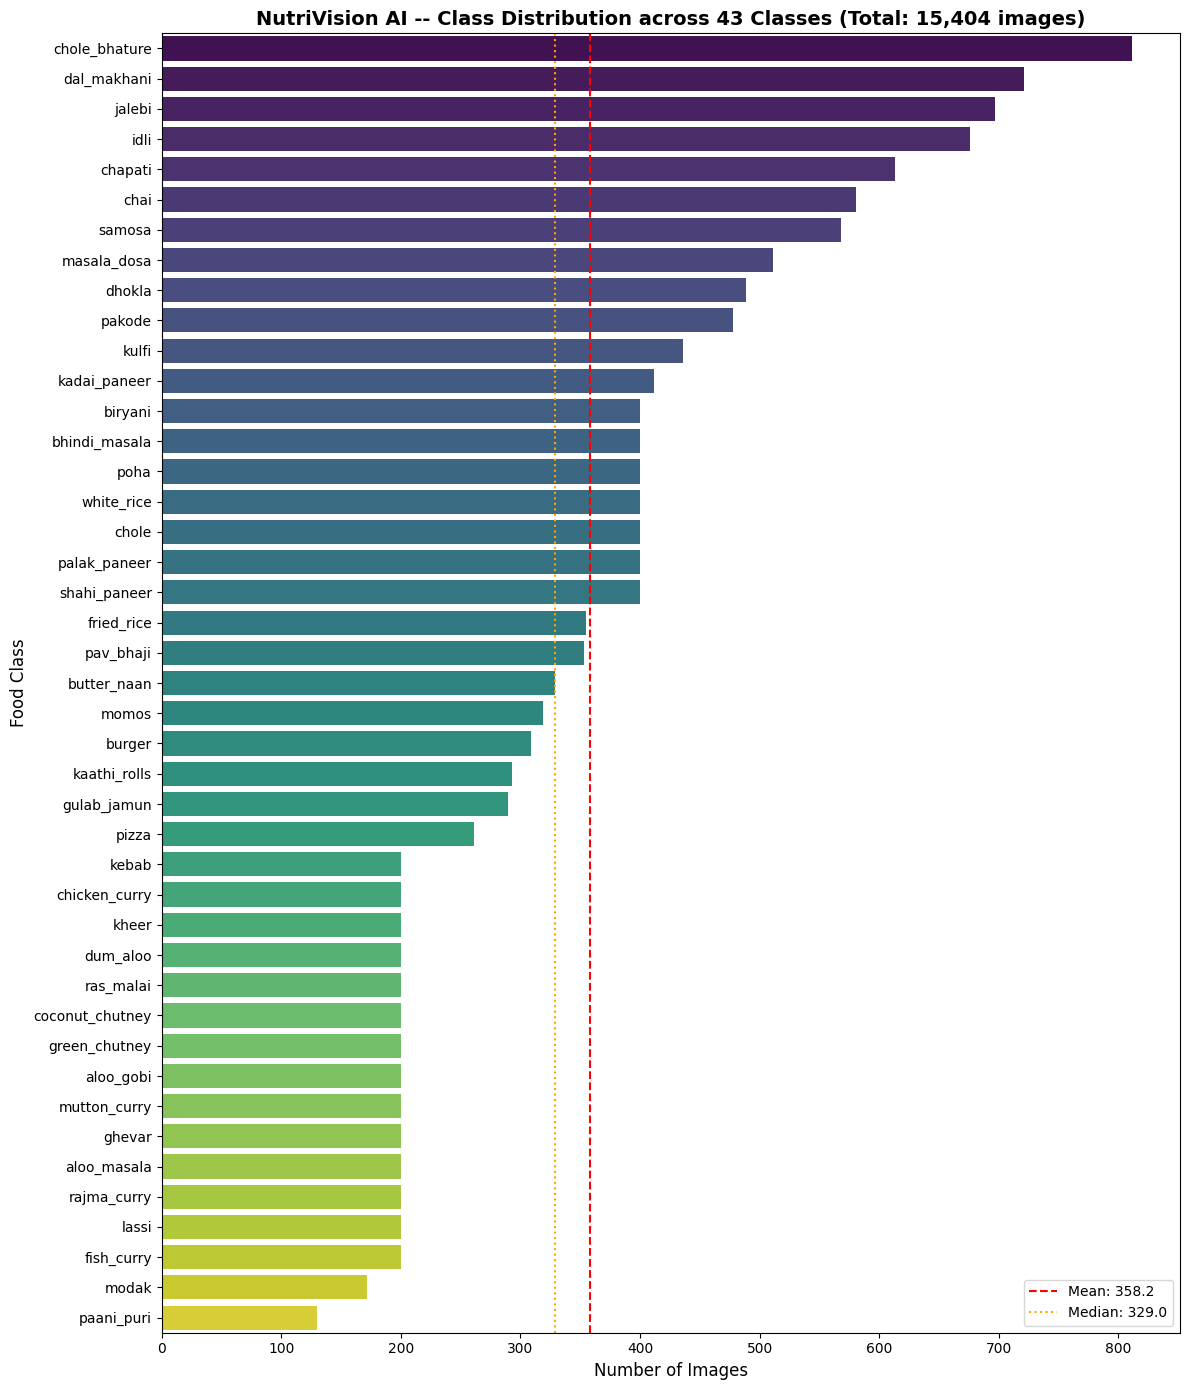

In [22]:
total_counts = Counter()
for labels in split_labels.values():
    total_counts.update(labels)

df_dist = pd.DataFrame(total_counts.most_common(), columns=["Food Class", "Image Count"])
print(f"Total Images: {df_dist['Image Count'].sum()}")
print(f"Max class count: {df_dist['Image Count'].max()} ({df_dist.iloc[0]['Food Class']})")
print(f"Min class count: {df_dist['Image Count'].min()} ({df_dist.iloc[-1]['Food Class']})")
imbalance_ratio = df_dist['Image Count'].max() / df_dist['Image Count'].min()
print(f"Class Imbalance Ratio: {imbalance_ratio:.2f}x")

# Plot Class Distribution
plt.figure(figsize=(12, 14))
sns.barplot(data=df_dist, x="Image Count", y="Food Class", palette="viridis")
plt.title(f"NutriVision AI -- Class Distribution across 43 Classes (Total: {df_dist['Image Count'].sum():,} images)", fontsize=14, fontweight="bold")
plt.xlabel("Number of Images", fontsize=12)
plt.ylabel("Food Class", fontsize=12)
plt.axvline(df_dist["Image Count"].mean(), color="red", linestyle="--", label=f"Mean: {df_dist['Image Count'].mean():.1f}")
plt.axvline(df_dist["Image Count"].median(), color="orange", linestyle=":", label=f"Median: {df_dist['Image Count'].median():.1f}")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 7. Image Integrity, Color Modes & Resolution Check

Checking Image Integrity:   0%|          | 0/500 [00:00<?, ?it/s]


Sample Integrity Audit (500 images):
  - Corrupted Images: 0
  - Color Modes: {'RGB': 499, 'P': 1}
  - Min Resolution: 273 x 219
  - Max Resolution: 7360 x 4912
  - Mean Resolution: 767 x 716


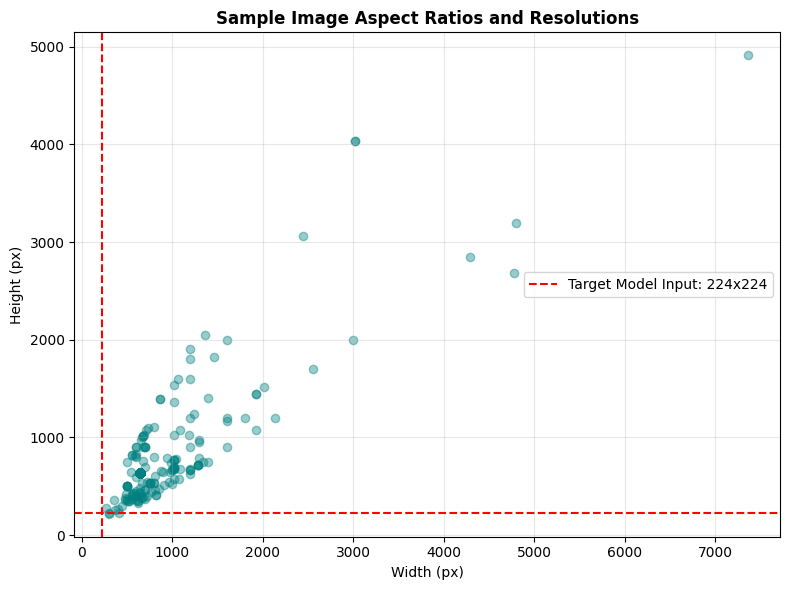

In [23]:
# Check a representative sample of 500 images for corruption, color mode, and resolution
sample_size = min(500, len(raw_dataset["train"]))
sample_indices = np.random.choice(len(raw_dataset["train"]), size=sample_size, replace=False)

resolutions = []
color_modes = Counter()
corrupted_count = 0

for idx in tqdm(sample_indices, desc="Checking Image Integrity"):
    try:
        sample = raw_dataset["train"][int(idx)]
        img = sample["image"]
        color_modes[img.mode] += 1
        resolutions.append(img.size) # (width, height)
    except Exception as e:
        corrupted_count += 1

widths, heights = zip(*resolutions)
print(f"\nSample Integrity Audit ({sample_size} images):")
print(f"  - Corrupted Images: {corrupted_count}")
print(f"  - Color Modes: {dict(color_modes)}")
print(f"  - Min Resolution: {min(widths)} x {min(heights)}")
print(f"  - Max Resolution: {max(widths)} x {max(heights)}")
print(f"  - Mean Resolution: {int(np.mean(widths))} x {int(np.mean(heights))}")

# Scatter plot of widths vs heights
plt.figure(figsize=(8, 6))
plt.scatter(widths, heights, alpha=0.4, color="teal")
plt.axvline(224, color="red", linestyle="--", label="Target Model Input: 224x224")
plt.axhline(224, color="red", linestyle="--")
plt.title("Sample Image Aspect Ratios and Resolutions", fontsize=12, fontweight="bold")
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Duplicate & Near-Duplicate Image Detection

In [25]:
def dhash(image, hash_size=8):
    img_gray = image.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.BILINEAR)
    pixels = list(img_gray.getdata())
    diff = []
    for row in range(hash_size):
        for col in range(hash_size):
            pixel_left = pixels[row * (hash_size + 1) + col]
            pixel_right = pixels[row * (hash_size + 1) + col + 1]
            diff.append(pixel_left > pixel_right)
    return sum([2 ** i for (i, v) in enumerate(diff) if v])

md5_hashes = set()
dhashes = set()
exact_dupes = 0
perceptual_dupes = 0

for idx in tqdm(sample_indices, desc="Scanning for duplicates"):
    img = raw_dataset["train"][int(idx)]["image"]
    # Exact byte hash
    b = BytesIO()
    img.save(b, format="JPEG")
    md5 = hashlib.md5(b.getvalue()).hexdigest()
    if md5 in md5_hashes:
        exact_dupes += 1
    else:
        md5_hashes.add(md5)
        
    # Perceptual hash
    ph = dhash(img)
    if ph in dhashes:
        perceptual_dupes += 1
    else:
        dhashes.add(ph)

print(f"\nDuplicate Scan Results on Sample ({sample_size} images):")
print(f"  - Exact Byte Duplicates: {exact_dupes}")
print(f"  - Near/Perceptual Duplicates: {perceptual_dupes}")


Scanning for duplicates:   0%|          | 0/500 [00:00<?, ?it/s]

C:\Users\anish\AppData\Local\Temp\ipykernel_6692\2731961397.py:3: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = list(img_gray.getdata())


OSError: cannot write mode P as JPEG

## 9. Visualizing Sample Food Images

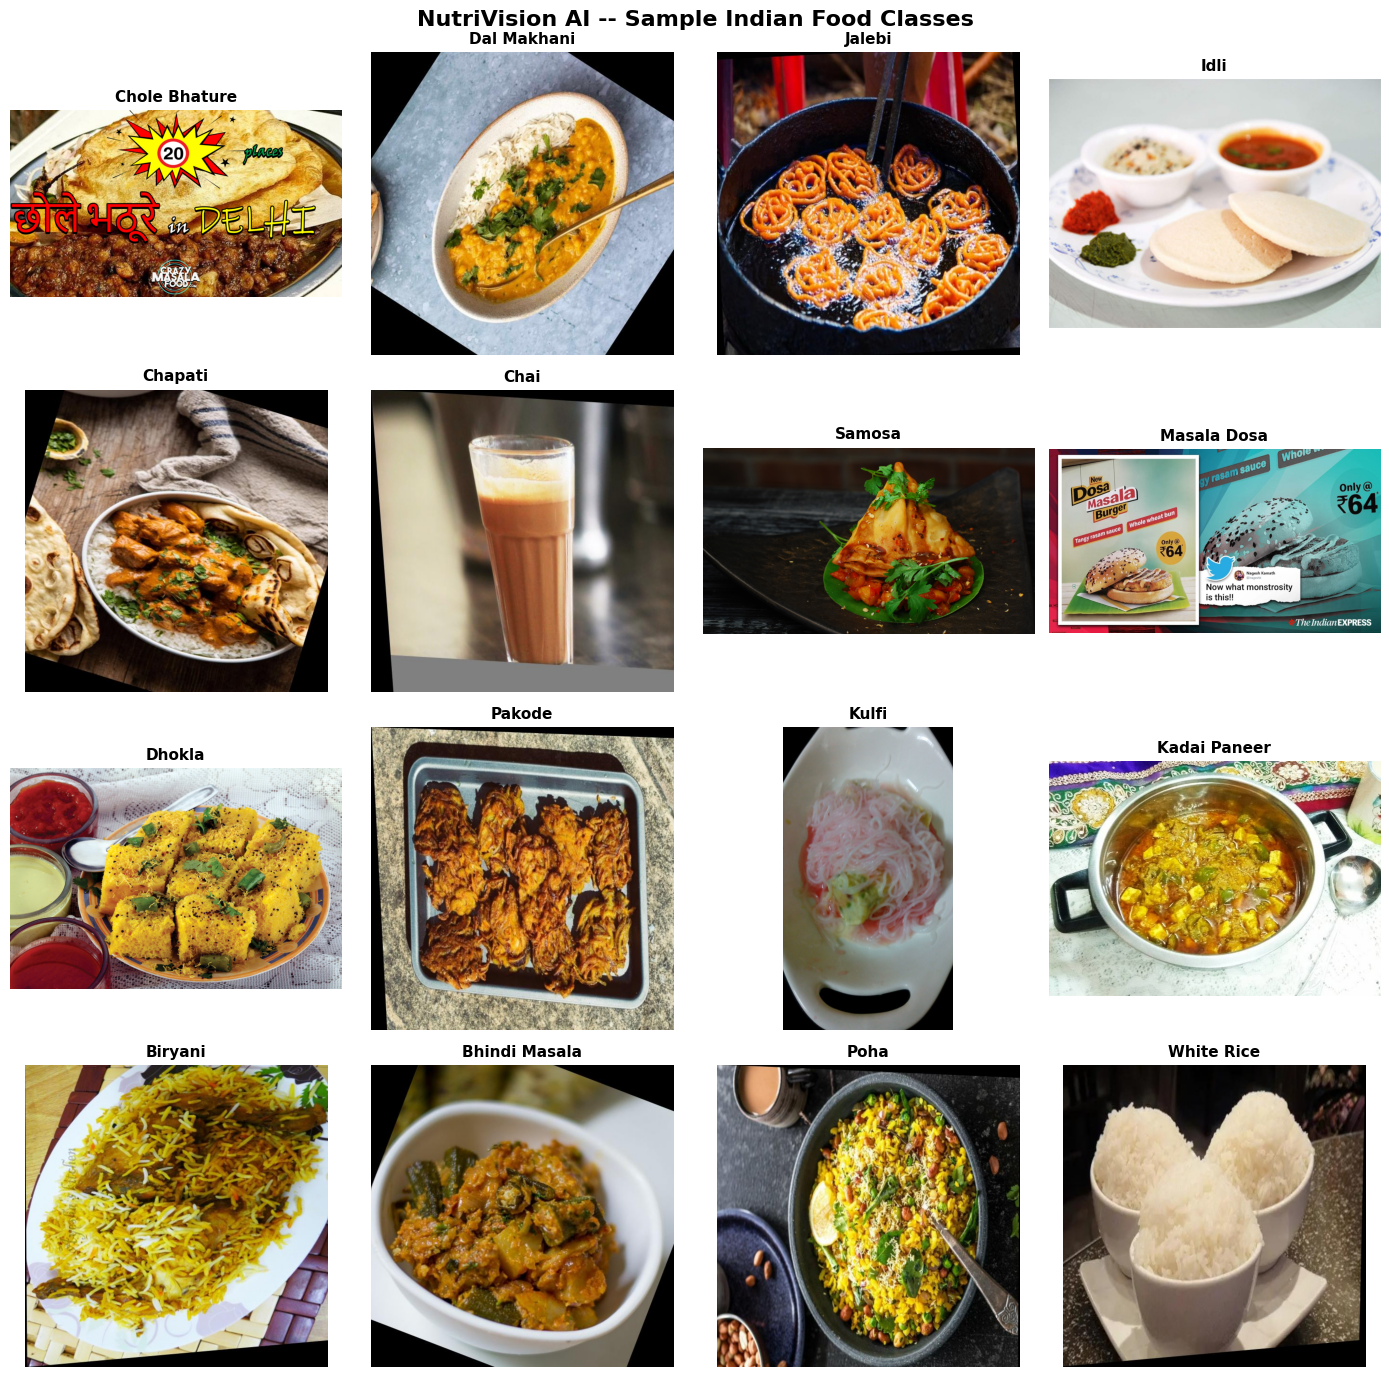

In [ ]:
# Visualize 16 distinct classes
sample_classes = df_dist["Food Class"].values[:16]

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
axes = axes.flatten()

for i, cls_name in enumerate(sample_classes):
    for item in raw_dataset["train"]:
        if item["label"] == cls_name:
            axes[i].imshow(item["image"])
            axes[i].set_title(cls_name.replace("_", " ").title(), fontsize=11, fontweight="bold")
            axes[i].axis("off")
            break

plt.suptitle("NutriVision AI -- Sample Indian Food Classes", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


## 10. Export Dataset Metadata and Exploration Artifacts

In [ ]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../data", exist_ok=True)

# 1. Export class names mapping
class_to_idx = {cls: idx for idx, cls in enumerate(all_unique_classes)}
idx_to_class = {idx: cls for idx, cls in enumerate(all_unique_classes)}

with open("../models/class_names.json", "w", encoding="utf-8") as f:
    json.dump({
        "classes": all_unique_classes,
        "class_to_idx": class_to_idx,
        "idx_to_class": idx_to_class,
        "total_classes": len(all_unique_classes)
    }, f, indent=2)

print(f"Saved ../models/class_names.json ({len(all_unique_classes)} classes)")

# 2. Export exploration summary
exploration_summary = {
    "dataset_repo": DATASET_REPO,
    "total_images": int(df_dist["Image Count"].sum()),
    "total_classes": len(all_unique_classes),
    "classes": all_unique_classes,
    "class_distribution": dict(total_counts),
    "annotation_type": "single_label_image_classification",
    "has_bounding_boxes": False,
    "has_segmentation": False,
    "upstream_split_flaw": {
        "val_classes_count": len(val_classes),
        "test_classes_count": len(test_classes),
        "missing_classes_count": len(missing_in_val),
        "missing_classes": sorted(list(missing_in_val))
    },
    "recommended_action": "Pool dataset and perform stratified 70/15/15 split across all 43 classes before training."
}

with open("../data/dataset_exploration_summary.json", "w", encoding="utf-8") as f:
    json.dump(exploration_summary, f, indent=2)

print("Saved ../data/dataset_exploration_summary.json")
print("\nNotebook 1 Exploration Complete! Ready for Notebook 2 (Preprocessing).")


Saved ../models/class_names.json (43 classes)
Saved ../data/dataset_exploration_summary.json

Notebook 1 Exploration Complete! Ready for Notebook 2 (Preprocessing).
